# 01 · Exploratory data analysis

What kind of data do we have, and what does it mean for the models we have to build?

1. Sanity checks
2. What the image features are
3. What the sentiment features are
4. Train vs. test: are they from the same distribution?
5. Dimensionality (PCA)
6. Class structure: how separable are the classes?
7. Summary and implications for each model

Descriptive statistics use the full training files. Anything that resembles a model
(the nearest-centroid baselines in §6) is fitted on the saved **train** split and
scored on the **validation** split, so these numbers are comparable with later results.
Figures are saved to `results/figures/eda_*.png`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from comp472_project.config import DATA_DIR, FIGURES_DIR, SEED, TASKS, seed_everything
from comp472_project.data import load_test, load_train

seed_everything()
rng = np.random.default_rng(SEED)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

# Chart style: recessive axes/grid, thin marks, colours assigned by role.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
TASK_COLORS = {"image": "#2a78d6", "sentiment": "#eb6834"}
HIGHLIGHT = ["#2a78d6", "#eb6834", "#1baf7a"]
SENT_COLORS = {0: "#e34948", 1: "#898781", 2: "#2a78d6"}  # diverging: negative red, neutral gray, positive blue
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})


def save(fig, name):
    fig.savefig(FIGURES_DIR / f"eda_{name}.png", dpi=200, bbox_inches="tight")


train = {t: load_train(t) for t in TASKS}   # (ids, X, y)
test = {t: load_test(t) for t in TASKS}     # (ids, X)
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

## 1. Sanity checks

In [2]:
def row_keys(X):
    # One hashable key per row (its raw bytes), for finding exact duplicates.
    # Plain Python sets/dicts: pandas' isin() gives wrong answers on bytes keys.
    return [r.tobytes() for r in X]


summary = {}
for task, cfg in TASKS.items():
    ids, X, y = train[task]
    test_ids, X_test = test[task]
    k_train, k_test = row_keys(X), row_keys(X_test)
    train_set = set(k_train)
    counts = np.bincount(y)
    sample_ids = sample.loc[sample["id"].str.startswith(cfg["test_id_prefix"]), "id"]
    summary[task] = {
        "train rows": len(X),
        "test rows": len(X_test),
        "features": X.shape[1],
        "NaN / inf values": int((~np.isfinite(X)).sum() + (~np.isfinite(X_test)).sum()),
        "label range": f"{y.min()}–{y.max()}",
        "train rows per class": f"{counts.min()}–{counts.max()}",
        "duplicate rows within train": len(k_train) - len(train_set),
        "duplicate rows within test": len(k_test) - len(set(k_test)),
        "test rows identical to a train row": sum(k in train_set for k in k_test),
        "test ids match sample_submission": set(test_ids) == set(sample_ids),
    }
pd.DataFrame(summary)

,image,sentiment
train rows,20000,12000
test rows,5000,5000
features,500,768
NaN / inf values,0,0
label range,0–49,0–2
train rows per class,400–400,4000–4000
duplicate rows within train,3,0
duplicate rows within test,0,1
test rows identical to a train row,3,0
test ids match sample_submission,True,True


In [3]:
# The image duplicates within train: do they agree on the label?
from collections import defaultdict

ids, X, y = train["image"]
rows_by_key = defaultdict(list)
for i, key in enumerate(row_keys(X)):
    rows_by_key[key].append(i)
dup_groups = [g for g in rows_by_key.values() if len(g) > 1]
pd.DataFrame([{"group": n, "id": ids[i], "label": y[i]} for n, g in enumerate(dup_groups) for i in g])

,group,id,label
0,0,img_train_000107,16
1,0,img_train_017148,16
2,1,img_train_001942,5
3,1,img_train_010874,5
4,2,img_train_012573,9
5,2,img_train_015900,9


In [4]:
# Image test rows that exactly match a training row (ids only).
test_ids, X_test = test["image"]
pd.DataFrame([{"test id": test_ids[j], "identical train row": ids[rows_by_key[k][0]]}
              for j, k in enumerate(row_keys(X_test)) if k in rows_by_key])

,test id,identical train row
0,img_000510,img_train_000731
1,img_003074,img_train_003915
2,img_004158,img_train_018339


**The data is clean.** No missing values; both training sets are perfectly balanced
(400 images per class, 4,000 texts per class); test ids match the submission template.

The few duplicates are harmless: 3 pairs of identical image rows in train (each pair has
the same label), 3 image test rows that are exact copies of training rows, and one
repeated text in the sentiment test set. At most a handful of duplicates can land on
both sides of our train/validation split, which is negligible against 4,000 validation rows.

## 2. What are the image features?

In [5]:
ids, X, y = train["image"]
norms = np.linalg.norm(X, axis=1)
nonzero = (X > 0).sum(axis=1)
print(f"value range:        {X.min():.3f} to {X.max():.3f}  (negative values: {(X < 0).sum()})")
print(f"zeros:              {(X == 0).mean():.1%} of all values")
print(f"row L2 norm:        {norms.min():.4f} to {norms.max():.4f}")
print(f"non-zero per image: median {np.median(nonzero):.0f}, 5th–95th pct {np.percentile(nonzero, 5):.0f}–{np.percentile(nonzero, 95):.0f} (of 500)")

value range:        0.000 to 0.923  (negative values: 0)
zeros:              85.2% of all values
row L2 norm:        1.0000 to 1.0000
non-zero per image: median 61, 5th–95th pct 28–141 (of 500)


**Can we get the original counts back?** Every row has length 1. The usual way to get a length of 1 is to take some vector and divide every value in it by that vector's length. Our guess is that the original vector held counts: how many times each of the 500 features showed up in the image. Call the original vector's length $L$. If the guess is right, every value in the row is a count divided by the same $L$:
$$
x_i = \frac{\text{count}_i}{L}
$$
We don't know $L$, but we can get rid of it. Take the smallest non-zero value in the row and call it $x_{\min}$. (We skip the zeros because we can't divide by zero.) Now divide every non-zero value by $x_{\min}$:
$$
\frac{x_i}{x_{\min}} = \frac{\text{count}_i / L}{\text{count}_{\min} / L} = \frac{\text{count}_i}{\text{count}_{\min}}
$$
The $L$ on the top and the $L$ on the bottom cancel out. What's left is a feature's count divided by the smallest count in the image. The code calls these divided values "ratios"

**Example.** In the first training image, the smallest non-zero value is 0.1187. Another
value is 0.4747, and $0.4747 / 0.1187 = 4$. So that feature showed up 4 times as often as
the least common feature in the image.

Because every count was divided by the same $L$, the feature with the smallest value is also the feature with the smallest count. So dividing by $x_{\min}$ is the same as dividing every count by the smallest count, and that feature becomes 1 (it's divided by itself).

If the smallest count really was 1, dividing by it changes nothing, and we get the true counts back. If it was 2, everything we get is half the true count: true counts 2, 4, 8 would come out as 1, 2, 4. We can't tell these two cases apart directly, so we assume the smallest count is 1. In the first image, 39 of its 44 non-zero features share that smallest value, which fits "seen once".

**The test.** Counts are whole numbers: a feature can't show up 2.5 times. So if our guess is right, every divided value should be a whole number (1, 2, 4, …), apart from tiny rounding errors from how computers store decimals. If the values were arbitrary, that would almost never happen. The next cell checks this for every row.

In [6]:
def count_ratios(row):
    nz = row[row > 0]
    return nz / nz.min()


ratios = [count_ratios(r) for r in X]
is_integer = np.array([np.allclose(q, np.round(q), atol=1e-3) for q in ratios])
implied_total = np.array([np.round(q).sum() for q in ratios])
print(f"rows whose non-zero values are integer multiples of each other: {is_integer.mean():.1%}")
print(f"implied total count per image (if the smallest count is 1): median {np.median(implied_total):.0f}, "
      f"5th–95th pct {np.percentile(implied_total, 5):.0f}–{np.percentile(implied_total, 95):.0f}")

rows whose non-zero values are integer multiples of each other: 100.0%
implied total count per image (if the smallest count is 1): median 72, 5th–95th pct 31–193


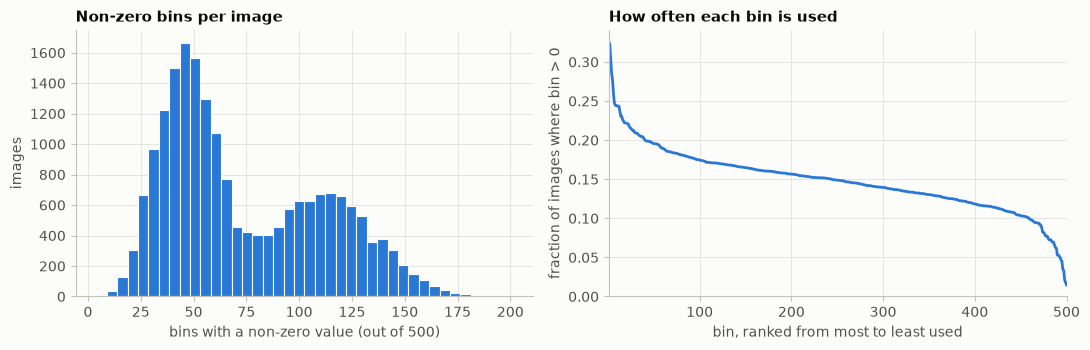

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
ax.hist(nonzero, bins=40, color=TASK_COLORS["image"], edgecolor=SURFACE, linewidth=0.8)
ax.set(title="Non-zero bins per image", xlabel="bins with a non-zero value (out of 500)", ylabel="images")

ax = axes[1]
usage = np.sort((X > 0).mean(axis=0))[::-1]
ax.plot(np.arange(1, 501), usage, color=TASK_COLORS["image"], lw=2)
ax.set(title="How often each bin is used", xlabel="bin, ranked from most to least used",
       ylabel="fraction of images where bin > 0", ylim=(0, None), xlim=(1, 500))

fig.tight_layout()
save(fig, "image_sparsity")

the plot on the right tells us that no feature is in most images, at mmost a feature can be found in ~33% of images. however, every feature is used by at least some images, so none can be dropped.

the left histogram is **bimodal**: one group of images uses ~50 bins, another ~115. is that
a class property?

In [8]:
dense = nonzero > 80  # the valley between the two peaks
dense_test = (test["image"][1] > 0).sum(axis=1) > 80
per_class = np.array([dense[y == c].mean() for c in range(50)])
print(f"images in the denser group: train {dense.mean():.0%}, test {dense_test.mean():.0%}")
print(f"share of each class in the denser group: {per_class.min():.0%} to {per_class.max():.0%}")
print(f"correlation of non-zero bins with total count: {np.corrcoef(nonzero, implied_total)[0, 1]:.2f}")

images in the denser group: train 38%, test 39%
share of each class in the denser group: 29% to 50%
correlation of non-zero bins with total count: 0.98


In [9]:
from comp472_project.preprocessing import Standardizer

# What standardising does to sparse features: rare bins have tiny std, so when they do fire, z is huge.
z = Standardizer().fit_transform(X)
print(f"feature std range: {X.std(0).min():.4f} to {X.std(0).max():.4f}")
print(f"max |z| after standardising: {np.abs(z).max():.1f}   (99.9th pct of |z|: {np.percentile(np.abs(z), 99.9):.1f})")

feature std range: 0.0074 to 0.0990
max |z| after standardising: 22.2   (99.9th pct of |z|: 7.1)


### What we now know about the image features

**Every row is a table of whole-number counts, divided by its length.** All 20,000 rows passed
the test above. So each of the 500 features counts how many times *something* showed up in the
image. With the smallest count taken as 1, an image has about 30–190 counts in total, spread
over about 30–140 of its 500 features.

**What is being counted?** The data description only says "a pretrained visual feature
extractor". The best-known extractor that outputs counts is **bag-of-visual-words**:

1. Cut the image into many small patches (for example around corners and edges).
2. Match each patch to the closest of 500 typical patch types (the "visual words"). This list
   of 500 was built beforehand from other images, which is the "pretrained" part.
3. Count how many patches matched each of the 500 types. That's the row, before dividing by
   its length.

Two things fit this explanation:

- **The counts are small (about 30–190 per image).** Another common image feature, a colour
  histogram, counts pixels, which would give thousands of counts per image. A few dozen to a
  couple hundred fits "number of patches found in an image".
- **500 is a typical round number for the size of the patch list.**

We can't fully prove this, because the dataset never says which extractor was used. So we say
the features are **consistent with** bag-of-visual-words. The part we *have* proven is that
they are counts. From here on, "feature $j$" and "visual word $j$" mean the same thing.

**The two groups of images (the two humps).** The sparse group uses fewer than 80 features and
the dense group more than 80:

- **They don't match the classes.** Every class has between 29% and 50% of its images in the
  dense group. If the groups were classes, some classes would be all dense and others all
  sparse. Still, 29% vs. 50% is a real spread, so the groups may be slightly linked to class.
- **The test set has the same mix as training** (39% vs. 38% dense), so the groups won't
  surprise our models on Kaggle.
- **Dense images simply had more counted.** The number of non-zero features and the total
  count rise and fall together almost perfectly (correlation 0.98).

*Why* some images had more counted is a guess. For example, larger or more detailed photos
give more patches, so more counts and more features used. We can't check this without the
original images. Either way, it's worth checking in the error analysis whether our models do
worse on one group than the other.

### What this means for the models

- **k-NN:**
  - **Euclidean and cosine distance will give the same neighbours on the raw features.**
    Cosine similarity measures the angle between two vectors (1 = pointing the same way).
    When every row has length 1, $\|a-b\|^2 = \|a\|^2 + \|b\|^2 - 2\,a \cdot b = 2 - 2\cos(a,b)$.
    So a smaller distance always means a larger cosine similarity, and both pick the same
    nearest neighbours. If our Euclidean and cosine k-NN results come out the same, this is
    why. It's not a bug.
  - **`L2Normalizer` does nothing here:** every row already has length 1.
  - **Standardising might hurt.** Standardising subtracts each feature's average and divides
    by its standard deviation (how much it usually varies). A feature that is 0 in almost
    every image barely varies, so its standard deviation is tiny (as low as 0.0074). On the
    rare occasion that feature isn't 0, dividing by that tiny number gives a huge value (up
    to 22, when typical values are below 1). k-NN adds up the squared differences across all
    features, so that one rare feature can outweigh everything else. We should test raw vs.
    standardised features instead of assuming standardising helps.
- **Decision trees and random forests:** a split asks "is feature $j$ above some value?",
  which here means "did visual word $j$ show up at least this many times?". Scaling a feature
  doesn't change which images end up on which side of a split, so scaling doesn't matter for
  trees.
- **Neural network:** the inputs are small (all below 1) and mostly zero. Standardising might
  help training, but it could also blow up rare features the same way it does for k-NN. Test
  both.

## 3. What are the sentiment features?

Mean-pooled `bert-base-uncased` token embeddings, 768 dimensions.

In [11]:
ids, X, y = train["sentiment"]
mean, std = X.mean(axis=0), X.std(axis=0)
norms = np.linalg.norm(X, axis=1)
print(f"value range:  {X.min():.2f} to {X.max():.2f};  zeros: {(X == 0).mean():.1%}")
print(f"% negative :  {(X < 0).mean():.1%}")
print(f"row L2 norm:  {norms.min():.2f} to {norms.max():.2f} (median {np.median(norms):.2f})")
print(f"feature std:  {std.min():.3f} to {std.max():.3f}")

top = np.argsort(-np.abs(mean))[:5]
pd.DataFrame({"dimension": top, "mean": mean[top], "std": std[top]}).set_index("dimension")

value range:  -5.07 to 1.75;  zeros: 0.0%
% negative :  51.6%
row L2 norm:  7.59 to 13.60 (median 8.88)
feature std:  0.147 to 0.630


,mean,std
dimension,,
308,-3.478,0.630
180,-0.877,0.244
123,0.854,0.210
381,-0.821,0.150
352,0.791,0.200


feature 308 has an average that is further from 0 than every other feature. this tells us that most tweets have been given a value of -3.5 ±0.63, that is suspicious.

In [11]:
d = top[0]
print(f"dimension {d}: share of the average squared row norm  {np.mean(X[:, d] ** 2) / np.mean((X ** 2).sum(1)):.1%}")
print(f"dimension {d}: share of total variance                {std[d] ** 2 / (std ** 2).sum():.1%}")
Xn = X / np.linalg.norm(X, axis=1, keepdims=True)
Xc = (X - mean) / np.linalg.norm(X - mean, axis=1, keepdims=True)
i, j = rng.integers(0, len(X), (2, 50_000))
print(f"mean cosine similarity of random pairs: raw {np.mean((Xn[i] * Xn[j]).sum(1)):.3f}, "
      f"after centring {np.mean((Xc[i] * Xc[j]).sum(1)):.3f}")

dimension 308: share of the average squared row norm  15.6%
dimension 308: share of total variance                1.4%
mean cosine similarity of random pairs: raw 0.653, after centring -0.000


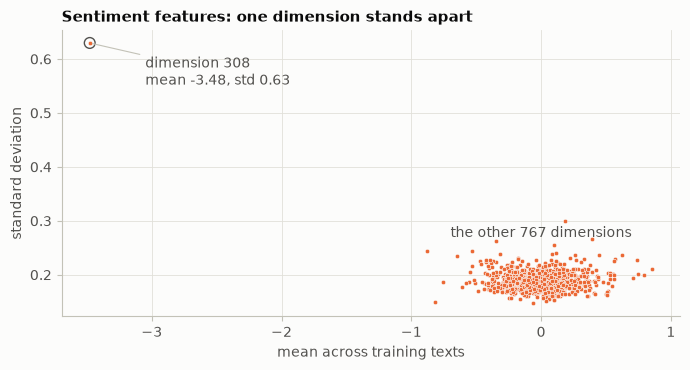

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(mean, std, s=10, color=TASK_COLORS["sentiment"], edgecolor=SURFACE, linewidth=0.4)
ax.scatter([mean[d]], [std[d]], s=60, facecolor="none", edgecolor=INK2, linewidth=1)
ax.annotate(f"dimension {d}\nmean {mean[d]:.2f}, std {std[d]:.2f}", (mean[d], std[d]),
            xytext=(40, -30), textcoords="offset points", color=INK2,
            arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8))
ax.annotate("the other 767 dimensions", (0, 0.27), ha="center", color=INK2)
ax.set(title="Sentiment features: one dimension stands apart",
       xlabel="mean across training texts", ylabel="standard deviation")
fig.tight_layout()
save(fig, "sentiment_dims")

The sentiment features are **dense, signed and not normalised** (row norms ≈ 7–14).

One dimension (308) has a mean of about −3.5 while every other dimension's mean lies within
±0.9. This is a known quirk of BERT ("rogue" or outlier dimensions). Its effect is subtle:

- It is a large **constant offset** shared by every text: ~15% of each vector's squared length.
  This is why raw cosine similarity between *any* two texts is ~0.65. All vectors point
  in roughly the same direction. Centring (subtracting the training mean) removes it.
- It contributes only ~1.4% of the **variance**, so it does *not* dominate Euclidean distances
  between texts. Feature stds only range over ~4×, so standardising changes Euclidean k-NN
  much less here than on the image features.

For k-NN with cosine distance, **centre (or standardise) first**. For the neural network,
standardising is the usual safe default.

## 4. Train vs. test: do they come from the same distribution?

Our validation accuracy only predicts Kaggle accuracy if the test set looks like the
training set. Two checks, both using only the (unlabelled) test features:

- **Per-feature shift**: how far each feature's test mean is from its train mean, in units of
  the training std.
- **Can train and test be told apart?** Compute the direction between the train and test means
  on one half of each set, project the other half onto it, and measure the AUC. 0.5 means they
  can't be told apart, 1.0 means they are perfectly separable.

In [13]:
from sklearn.metrics import roc_auc_score

def shift_report(task):
    _, X, _ = train[task]
    _, X_test = test[task]
    s = Standardizer().fit(X)
    A, B = s.transform(X), s.transform(X_test)
    shift = B.mean(axis=0)  # train mean is 0 after standardising, so this is the shift in std units
    ia, ib = rng.permutation(len(A)), rng.permutation(len(B))
    ha, hb = len(A) // 2, len(B) // 2
    w = B[ib[:hb]].mean(0) - A[ia[:ha]].mean(0)
    scores = np.concatenate([A[ia[ha:]] @ w, B[ib[hb:]] @ w])
    is_test = np.r_[np.zeros(len(A) - ha), np.ones(len(B) - hb)]
    return shift, roc_auc_score(is_test, scores)


shifts, aucs = {}, {}
for task in TASKS:
    shifts[task], aucs[task] = shift_report(task)
pd.DataFrame({
    task: {
        "median |shift| (std units)": np.median(np.abs(shifts[task])),
        "max |shift| (std units)": np.abs(shifts[task]).max(),
        "features with |shift| > 0.25": int((np.abs(shifts[task]) > 0.25).sum()),
        "train-vs-test AUC": aucs[task],
    }
    for task in TASKS
})

,image,sentiment
median |shift| (std units),0.010,0.184
max |shift| (std units),0.049,0.768
features with |shift| > 0.25,0.000,271.000
train-vs-test AUC,0.492,0.872


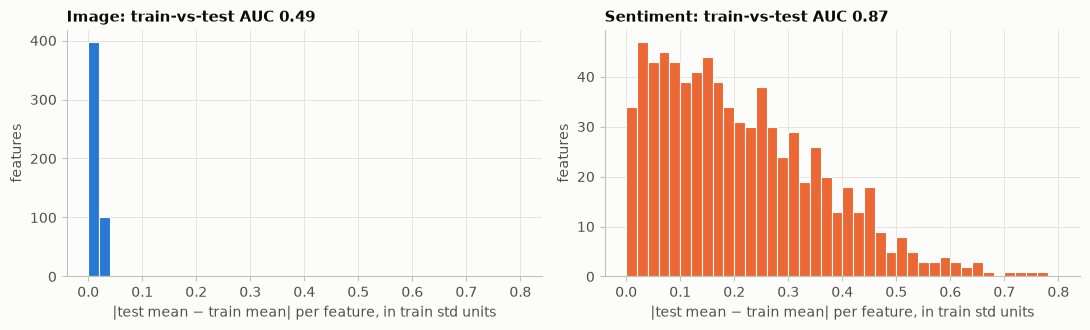

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, task in zip(axes, TASKS):
    ax.hist(np.abs(shifts[task]), bins=np.linspace(0, 0.8, 41), color=TASK_COLORS[task],
            edgecolor=SURFACE, linewidth=0.8)
    ax.set(title=f"{task.capitalize()}: train-vs-test AUC {aucs[task]:.2f}",
           xlabel="|test mean − train mean| per feature, in train std units", ylabel="features")
fig.tight_layout()
save(fig, "train_test_shift")

from the above, we know that image test and training data are quite similar, so we can be more confident in our validation scores because the data we validate on is similar to the data we will be tested on. sentiment test data however is noticeably different from our given training data. so we shouldn't prioritize validation scores only, and there's even a chance that tuning too hard on the validation will overfit the model to the validation set and it will perform poorly on the test set (that's always a chance but more likely here). this can also be used as an explanation as to why our model may not perform very well, because our training and validation sets are different from the test set, so the final test score might be lower than our validation scores. we should prefer models that do well across many settings over the single best validation score and use regularisation in the neural network. 

Is the sentiment shift just a different **class mix** in the test set (e.g. more neutral tweets)? If so, the test mean would lie between the class means. Compare the shift on the most-shifted features with how far apart the class means are on those same features:

In [14]:
from comp472_project.config import SENTIMENT_LABELS

_, X, y = train["sentiment"]
s = Standardizer().fit(X)
Z = s.transform(X)
class_means = np.stack([Z[y == c].mean(0) for c in range(3)])
most = np.argsort(-np.abs(shifts["sentiment"]))[:6]
pd.DataFrame({
    "test shift": shifts["sentiment"][most],
    **{f"{SENTIMENT_LABELS[c].lower()} mean": class_means[c, most] for c in range(3)},
}, index=pd.Index(most, name="dimension"))

,test shift,negative mean,neutral mean,positive mean
dimension,,,,
129,0.768,0.261,-0.087,-0.174
221,-0.743,-0.231,0.096,0.135
463,-0.722,0.200,-0.094,-0.106
369,0.714,0.048,-0.145,0.096
520,-0.664,-0.275,0.080,0.195
292,0.656,0.160,0.038,-0.198


For feature 129, the whole test set's average is 0.768 training standard deviations from the training average. In training, the three sentiments' averages on that feature range only from −0.174 to 0.261. Any mix of sentiments would have to land in that range, and 0.768 doesn't. So the shift can't be just a different class mix. The test tweets themselves are different.

- **Image: no shift.** Train and test can't be told apart (AUC ≈ 0.5) and no feature moves
  by more than 0.05 std. Validation accuracy on images should be a reliable estimate of
  Kaggle accuracy.
- **Sentiment: clear covariate shift.** Train and test are fairly separable (AUC ≈ 0.87).
  271 of the 768 features shift by more than 0.25 std, the largest by ~0.77. The shifts are **larger than the gap between any two
  class means** on the same features, so a different class mix cannot explain them. The test
  texts themselves look different from the training texts. This is plausible for TweetEval,
  whose test tweets were collected separately from its training tweets (different time
  period, so different topics and vocabulary).

What this means:

1. **Expect sentiment validation accuracy to be optimistic.** The Kaggle sentiment score
   will probably come in lower, and we can't measure the gap locally. Comparing the public
   leaderboard against validation will tell us roughly how big it is.
2. **Don't over-tune sentiment models to the validation split.** Gains of a fraction of a
   percent on validation may not transfer. Prefer models and settings that are stable
   across a range of hyperparameters (and regularised neural networks).
3. Preprocessing is still fitted on training data only, never on the test features.
4. The test set's class proportions are also unknown. Train and validation are balanced
   (1/3 each), but the original TweetEval test set is not.

## 5. Dimensionality: how many directions carry the variance?

PCA via SVD of the centred training data (descriptive only. When PCA is used for modelling,
it must be fitted on the train split).

In [15]:
def explained_variance_ratio(X):
    sv = np.linalg.svd(X - X.mean(axis=0), compute_uv=False)
    return sv ** 2 / (sv ** 2).sum()


evr = {task: explained_variance_ratio(train[task][1]) for task in TASKS}
thresholds = [0.5, 0.8, 0.9, 0.95, 0.99]
pd.DataFrame(
    {task: [int(np.searchsorted(np.cumsum(evr[task]), q) + 1) for q in thresholds] for task in TASKS},
    index=pd.Index([f"{q:.0%}" for q in thresholds], name="variance kept"),
).assign(
    **{
        "image (% of dims)": lambda d: d["image"] / 500,
        "sentiment (% of dims)": lambda d: d["sentiment"] / 768,
    }
).style.format({
    "image (% of dims)": "{:.1%}",
    "sentiment (% of dims)": "{:.1%}",
})

,image,sentiment,image (% of dims),sentiment (% of dims)
variance kept,,,,
50%,117,30,23.4%,3.9%
80%,291,130,58.2%,16.9%
90%,374,241,74.8%,31.4%
95%,426,373,85.2%,48.6%
99%,478,621,95.6%,80.9%


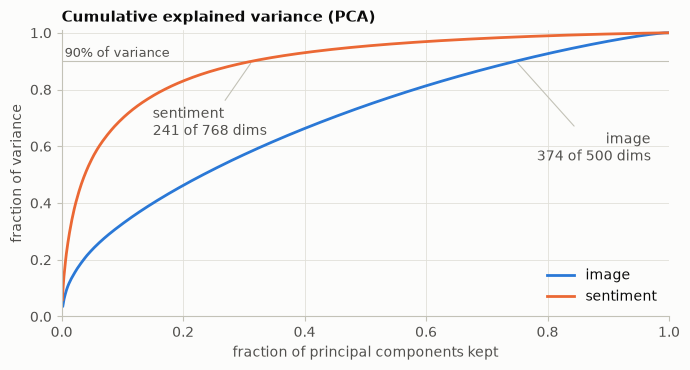

In [17]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(7, 3.8))
for task in TASKS:
    c = np.cumsum(evr[task])
    x = np.arange(1, len(c) + 1) / len(c)
    ax.plot(x, c, color=TASK_COLORS[task], lw=2)
    k90 = np.searchsorted(c, 0.9)
    text_xy, ha = ((0.15, 0.64), "left") if task == "sentiment" else ((0.97, 0.55), "right")
    ax.annotate(f"{task}\n{k90 + 1} of {len(c)} dims", (x[k90], 0.9), xytext=text_xy, ha=ha,
                color=INK2, arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8))
ax.axhline(0.9, color=AXIS, lw=0.8, zorder=0)
ax.text(0.005, 0.915, "90% of variance", color=INK2, fontsize=9)
ax.set(title="Cumulative explained variance (PCA)", xlabel="fraction of principal components kept",
       ylabel="fraction of variance", xlim=(0, 1), ylim=(0, 1.01))
ax.legend(handles=[Line2D([], [], color=TASK_COLORS[t], lw=2, label=t) for t in TASKS], loc="lower right")
fig.tight_layout()
save(fig, "pca_variance")

- **Image:** variance is spread almost evenly. 90% needs 374 of 500 components. That is typical of sparse word-count data: there are no few dominant directions, so PCA won't compress these features much without losing information.
- **Sentiment:** more concentrated at the start (30 components give 50%), then a long tail. PCA to ~100–250 dimensions could speed up k-NN with little loss, but *variance kept* is not *class information kept*, so measure the validation accuracy, don't assume it.

## 6. Class structure: how separable are the classes?

### 6a. Nearest-centroid baseline

The simplest possible classifier: represent each class by its mean training vector and assign
each validation example to the closest mean. It shows how much class information is carried by
"where the class sits on average". It is a reference point, not one of our models.

In [18]:
from comp472_project.data import load_split

def nearest_centroid(X_tr, y_tr, X_ev, metric):
    C = np.stack([X_tr[y_tr == c].mean(0) for c in np.unique(y_tr)])
    if metric == "cosine":
        C = C / np.linalg.norm(C, axis=1, keepdims=True)
        X_ev = X_ev / np.linalg.norm(X_ev, axis=1, keepdims=True)
        return (X_ev @ C.T).argmax(1)
    sq_dist = (X_ev ** 2).sum(1)[:, None] - 2 * X_ev @ C.T + (C ** 2).sum(1)
    return sq_dist.argmin(1)


splits = {task: load_split(task) for task in TASKS}
results = {}
for task, d in splits.items():
    row = {"chance": 1 / d.n_classes}
    for scaling in ("raw", "standardised"):
        if scaling == "raw":
            X_tr, X_va = d.X_train, d.X_val
        else:
            s = Standardizer().fit(d.X_train)
            X_tr, X_va = s.transform(d.X_train), s.transform(d.X_val)
        for metric in ("euclidean", "cosine"):
            row[f"{scaling}, {metric}"] = np.mean(nearest_centroid(X_tr, d.y_train, X_va, metric) == d.y_val)
    results[task] = row
pd.DataFrame(results).T

,chance,"raw, euclidean","raw, cosine","standardised, euclidean","standardised, cosine"
image,0.020,0.211,0.209,0.222,0.217
sentiment,0.333,0.568,0.570,0.575,0.572


Both tasks are well above chance, but far from solved by class means alone. On images (21% vs.
2% chance), a class's average histogram is a weak description of the class. Images of one
object vary a lot, so local methods (k-NN), non-linear ones (trees, the neural network) should
do much better. Preprocessing barely matters for this baseline on either task.

### 6b. Sentiment: is neutral the hard class?

Negative    0.669
Neutral     0.461
Positive    0.594
Name: recall, dtype: float64

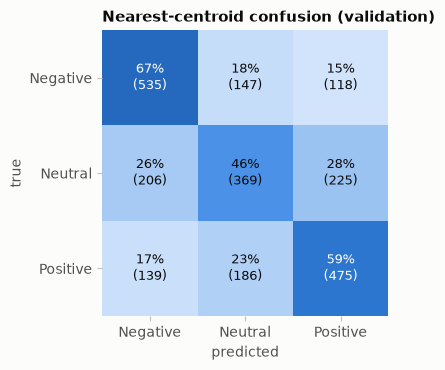

In [19]:
from comp472_project.evaluation import confusion_matrix, per_class_accuracy

d = splits["sentiment"]
s = Standardizer().fit(d.X_train)
pred = nearest_centroid(s.transform(d.X_train), d.y_train, s.transform(d.X_val), "euclidean")
cm = confusion_matrix(d.y_val, pred, 3)
names = [SENTIMENT_LABELS[c] for c in range(3)]
recall = per_class_accuracy(cm)

fig, ax = plt.subplots(figsize=(4.6, 3.8))
rates = cm / cm.sum(1, keepdims=True)
ax.imshow(rates, cmap=BLUES, vmin=0, vmax=1)
ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{rates[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=9,
                color="#ffffff" if rates[i, j] > 0.5 else INK)
ax.set_xticks(range(3), names)
ax.set_yticks(range(3), names)
ax.set(title="Nearest-centroid confusion (validation)", xlabel="predicted", ylabel="true")
for spine in ax.spines.values():
    spine.set_visible(False)
fig.tight_layout()
save(fig, "sentiment_confusion_centroid")

pd.Series(recall, index=names, name="recall")

In [20]:
# Geometry of the class centroids (after centring on the overall mean).
_, X, y = train["sentiment"]
C = np.stack([X[y == c].mean(0) for c in range(3)]) - X.mean(0)
Cn = C / np.linalg.norm(C, axis=1, keepdims=True)
dist = np.linalg.norm(C[:, None] - C[None], axis=-1)
print("distance between class centroids:")
print(pd.DataFrame(dist, index=names, columns=names).round(2))
print("\ncosine similarity of centred class centroids:")
print(pd.DataFrame(Cn @ Cn.T, index=names, columns=names).round(2))

distance between class centroids:
          Negative  Neutral  Positive
Negative      0.00     0.93      1.20
Neutral       0.93     0.00      0.82
Positive      1.20     0.82      0.00

cosine similarity of centred class centroids:
          Negative  Neutral  Positive
Negative      1.00    -0.43     -0.78
Neutral      -0.43     1.00     -0.22
Positive     -0.78    -0.22      1.00


Yes, and the geometry shows why. Negative and positive centroids point in nearly opposite
directions (cosine ≈ −0.78) and are furthest apart. **Neutral sits between them**, closer to
both. Neutral is recalled least often (~46%) and is confused with both sides roughly equally.
This is the "neutral is hardest" pattern the brief asks about, and it shows up before training
any real model. Expect every model's sentiment errors to concentrate on neutral.

### 6c. Image: which classes look alike?

Cosine similarity between class-mean histograms, with classes reordered by hierarchical
clustering so that similar classes sit next to each other.

pairwise similarity of class means: median 0.89, 5th–95th pct 0.72–0.95


,class a,class b,cosine similarity
0,21,22,0.972
1,35,36,0.970
2,37,39,0.969
3,20,22,0.967
4,22,29,0.966
5,22,24,0.966
6,22,23,0.964
7,20,21,0.963


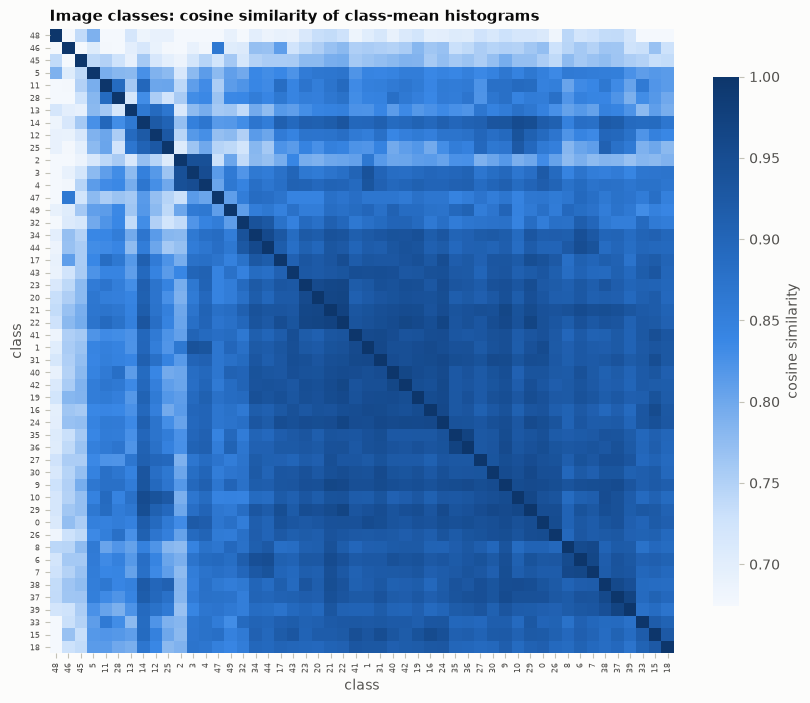

In [21]:
from scipy.cluster.hierarchy import leaves_list, linkage

_, X, y = train["image"]
C = np.stack([X[y == c].mean(0) for c in range(50)])
Cn = C / np.linalg.norm(C, axis=1, keepdims=True)
S = Cn @ Cn.T
order = leaves_list(linkage(Cn, method="average", metric="cosine"))

fig, ax = plt.subplots(figsize=(8.5, 7.5))
off_diag = S[~np.eye(50, dtype=bool)]
im = ax.imshow(S[np.ix_(order, order)], cmap=BLUES, vmin=np.percentile(off_diag, 1), vmax=1)
ax.grid(False)
ax.set_xticks(range(50), order, fontsize=6, rotation=90)
ax.set_yticks(range(50), order, fontsize=6)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set(title="Image classes: cosine similarity of class-mean histograms", xlabel="class", ylabel="class")
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.outline.set_visible(False)
cb.set_label("cosine similarity", color=INK2)
fig.tight_layout()
save(fig, "image_centroid_similarity")

iu = np.triu_indices(50, 1)
print(f"pairwise similarity of class means: median {np.median(S[iu]):.2f}, "
      f"5th–95th pct {np.percentile(S[iu], 5):.2f}–{np.percentile(S[iu], 95):.2f}")
top_pairs = np.argsort(-S[iu])[:8]
pd.DataFrame({"class a": iu[0][top_pairs], "class b": iu[1][top_pairs], "cosine similarity": S[iu][top_pairs]})

In [22]:
from comp472_project.evaluation import most_confused_pairs

# Where the nearest-centroid baseline fails on images.
d = splits["image"]
pred = nearest_centroid(d.X_train, d.y_train, d.X_val, "cosine")
cm_img = confusion_matrix(d.y_val, pred, 50)
recall_img = per_class_accuracy(cm_img)
print("hardest classes for the centroid baseline (recall):",
      ", ".join(f"{c}: {recall_img[c]:.0%}" for c in np.argsort(recall_img)[:6]))
print("easiest:", ", ".join(f"{c}: {recall_img[c]:.0%}" for c in np.argsort(recall_img)[::-1][:6]))
most_confused_pairs(cm_img, 8)

hardest classes for the centroid baseline (recall): 10: 0%, 29: 1%, 21: 2%, 9: 2%, 22: 4%, 31: 4%
easiest: 46: 62%, 5: 51%, 13: 50%, 11: 50%, 48: 50%, 2: 49%


,true,pred,count
0,4,2,22
1,3,2,16
2,7,8,16
3,27,25,13
4,13,46,12
5,37,39,12
6,20,14,12
7,10,25,12


All class means are quite similar (median pairwise cosine ≈ 0.89), which is why centroids
separate the classes poorly. A block of classes (around 20–24 and 29) is especially close.
Three of them (21, 22, 29) are also among the baseline's worst classes, so this is a good
group to watch in the error analysis. The most-confused pairs of the
baseline give a first list of "difficult" classes to check against the real models later. We
don't have the object names, so these stay class numbers.

### 6d. Are same-class examples more similar than different-class examples?

A model-free check: pick random pairs of training examples and compare the cosine similarity
of same-class pairs with different-class pairs (vectors centred first). AUC = probability that a
random same-class pair is more similar than a random different-class pair.

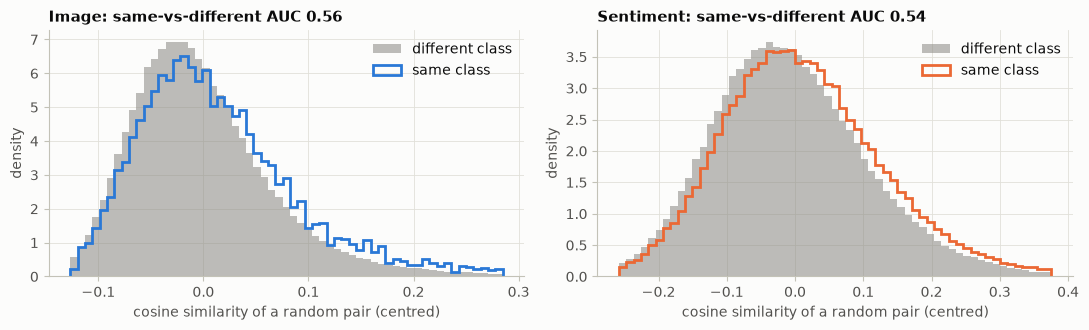

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
pair_auc = {}
for ax, task in zip(axes, TASKS):
    _, X, y = train[task]
    Xc = X - X.mean(0)
    Xc = Xc / np.linalg.norm(Xc, axis=1, keepdims=True)
    i, j = rng.integers(0, len(X), (2, 300_000))
    keep = i != j
    i, j = i[keep], j[keep]
    sim = (Xc[i] * Xc[j]).sum(1)
    same = y[i] == y[j]
    pair_auc[task] = roc_auc_score(same, sim)
    bins = np.linspace(np.percentile(sim, 0.5), np.percentile(sim, 99.5), 60)
    ax.hist(sim[~same], bins=bins, density=True, color=MUTED, alpha=0.55, label="different class")
    ax.hist(sim[same], bins=bins, density=True, histtype="step", color=TASK_COLORS[task], lw=2,
            label="same class")
    ax.set(title=f"{task.capitalize()}: same-vs-different AUC {pair_auc[task]:.2f}",
           xlabel="cosine similarity of a random pair (centred)", ylabel="density")
    ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "pair_similarity")

For images, compare that with pairs from the same **sparsity group** (§2), which has nothing
to do with the object:

In [24]:
_, X, y = train["image"]
Xc = X - X.mean(0)
Xc = Xc / np.linalg.norm(Xc, axis=1, keepdims=True)
i, j = rng.integers(0, len(X), (2, 300_000))
keep = i != j
i, j = i[keep], j[keep]
sim = (Xc[i] * Xc[j]).sum(1)
pd.Series({
    "same class vs. different class": roc_auc_score(y[i] == y[j], sim),
    "same sparsity group vs. different group": roc_auc_score(dense[i] == dense[j], sim),
}, name="pair-similarity AUC (image)")

same class vs. different class             0.561
same sparsity group vs. different group    0.714
Name: pair-similarity AUC (image), dtype: float64

The two class distributions overlap almost completely on **both** tasks (AUC ≈ 0.55). For
images, sharing a sparsity group makes two images much more similar (AUC ≈ 0.71) than sharing
an object class. The capture domain is a stronger signal in these features than the object. A typical
same-class pair is barely more similar than a typical different-class pair. Class information is
spread thinly across many dimensions, not visible in overall similarity. This does *not* mean
the tasks are hopeless. A classifier only needs the *nearest* neighbours or the *right* feature
combinations to be informative, not the average pair. But it does warn that k-NN's choice of
distance and preprocessing will matter, and that the sentiment task in particular has a low
ceiling with these frozen features.

### 6e. 2-D projections (t-SNE)

t-SNE places similar examples close together in 2-D. Local neighbourhoods are meaningful,
but distances between far-apart groups and cluster sizes are not. Run on a random subsample
after PCA to 50 dimensions.

In [25]:
from sklearn.manifold import TSNE

def tsne_2d(X, n, standardise):
    idx = rng.choice(len(X), n, replace=False)
    Z = Standardizer().fit_transform(X[idx]) if standardise else X[idx] - X[idx].mean(0)
    _, _, Vt = np.linalg.svd(Z, full_matrices=False)
    emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z @ Vt[:50].T)
    return idx, emb


_, X, y = train["sentiment"]
idx_s, emb_s = tsne_2d(X, 4000, standardise=True)
_, X, y = train["image"]
idx_i, emb_i = tsne_2d(X, 6000, standardise=False)

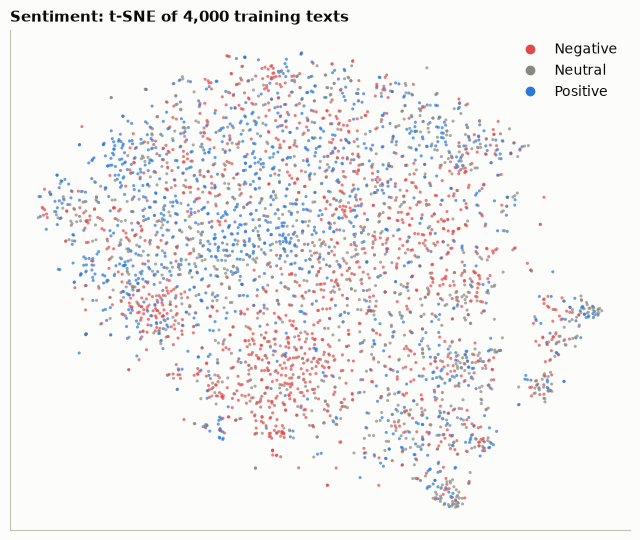

In [26]:
_, _, y = train["sentiment"]
ys = y[idx_s]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(emb_s[:, 0], emb_s[:, 1], s=5, c=[SENT_COLORS[c] for c in ys], alpha=0.7, linewidths=0)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=SENT_COLORS[c], label=SENTIMENT_LABELS[c]) for c in range(3)],
          loc="upper right")
ax.set(title="Sentiment: t-SNE of 4,000 training texts", xticks=[], yticks=[])
ax.grid(False)
fig.tight_layout()
save(fig, "sentiment_tsne")

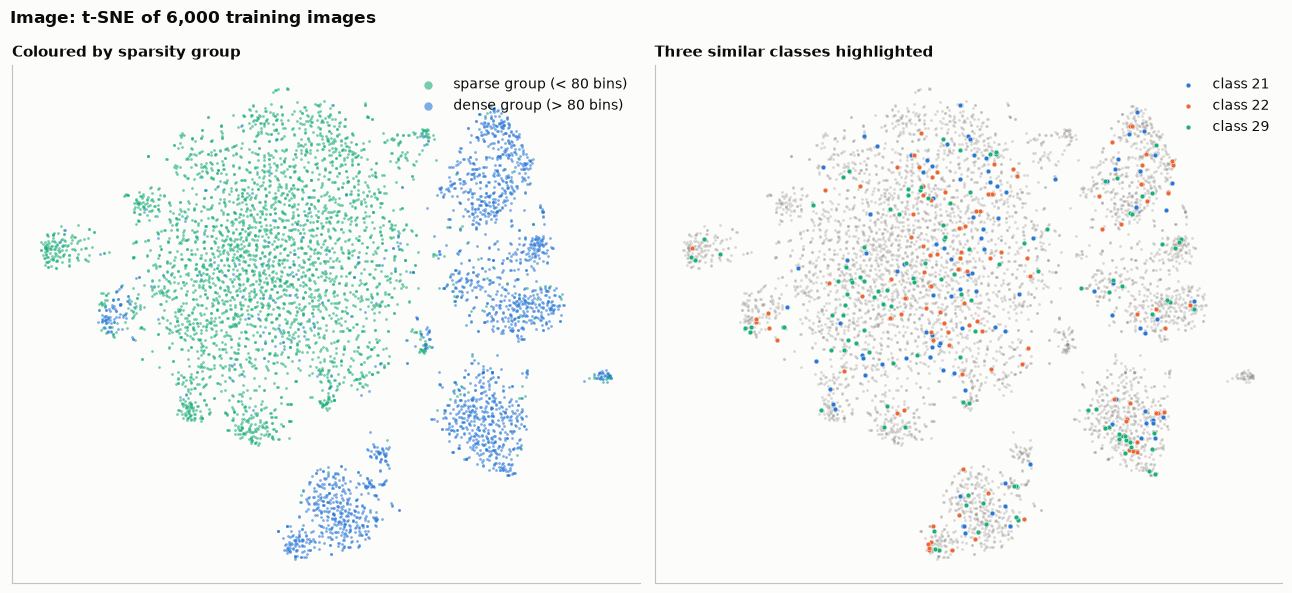

In [27]:
_, _, y = train["image"]
yi, di = y[idx_i], dense[idx_i]
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

ax = axes[0]
for flag, color, label in [(False, HIGHLIGHT[2], "sparse group (< 80 bins)"), (True, HIGHLIGHT[0], "dense group (> 80 bins)")]:
    m = di == flag
    ax.scatter(emb_i[m, 0], emb_i[m, 1], s=4, color=color, alpha=0.6, linewidths=0, label=label)
ax.legend(loc="upper right", markerscale=3)
ax.set(title="Coloured by sparsity group", xticks=[], yticks=[])

ax = axes[1]
group = [21, 22, 29]  # among the most similar class means (6c)
other = ~np.isin(yi, group)
ax.scatter(emb_i[other, 0], emb_i[other, 1], s=4, color=MUTED, alpha=0.3, linewidths=0)
for color, c in zip(HIGHLIGHT, group):
    m = yi == c
    ax.scatter(emb_i[m, 0], emb_i[m, 1], s=12, color=color, edgecolor=SURFACE, linewidth=0.3, label=f"class {c}")
ax.legend(loc="upper right")
ax.set(title="Three similar classes highlighted", xticks=[], yticks=[])

for ax in axes:
    ax.grid(False)
fig.suptitle("Image: t-SNE of 6,000 training images", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "image_tsne")

- **Sentiment:** there are broad regions where negative or positive texts dominate, with
  neutral spread through and between them, and no clean clusters. This fits §6b. For the
  clustering experiment, expect k-means with k=3 to find groups that only loosely line up
  with the three sentiments.
- **Image:** the picture splits into several separate islands, but they are **not classes**.
  Each island is almost entirely one sparsity group (left panel), and the highlighted classes
  appear in nearly every island (right panel). Every island holds a mix of all classes. The
  dominant structure is the capture domain (resolution/source), with the object class as a
  weaker signal *inside* each domain.

  Consequences:
  - **Clustering:** k-means on raw image features will most likely rediscover these domains,
    not the 50 objects. That's a good result to show and explain in the presentation (compare
    clusters with both the class labels *and* the sparsity group).
  - **k-NN:** an image's nearest neighbours will mostly come from its own domain. Since every
    domain contains every class, this isn't fatal, but it effectively shrinks the pool of
    useful neighbours. Larger `k` or distance weighting may matter more than usual.
  - **Error analysis:** compare accuracy on dense vs. sparse images.

## 7. Summary

| | Image | Sentiment |
|---|---|---|
| Representation | L2-normalised **count histograms** (bag-of-visual-words), 500 bins, ~85% zeros, non-negative. Two sparsity groups (~50 vs. ~115 bins used), not class-related | Dense, signed BERT mean-pooled embeddings, norms ≈ 7–14, one outlier dimension (308) |
| Data quality | Clean, balanced (400/class), 3 duplicate pairs | Clean, balanced (4,000/class) |
| Train vs. test | Same distribution (AUC ≈ 0.5) | **Covariate shift** (AUC ≈ 0.87). Validation accuracy likely optimistic |
| Dimensionality | Variance spread out (90% at 374/500 components) | More concentrated (90% at 241/768) |
| Class structure | Similar class means (centroid baseline 21% vs 2% chance). Strongest structure is the **capture domain** (t-SNE islands), not the class | Neutral sits between negative and positive and is hardest (centroid recall ~46%) |

### Implications for each model

- **k-NN:** raw image features already give cosine distance, so test *raw vs. standardised* (standardising may hurt sparse histograms) and consider a sqrt transform. For sentiment, centre/standardise before cosine. Train-set predictions with k=1 are trivially 100%. Use validation for everything.
- **Decision tree:** scaling is irrelevant. With 500–768 weak features and class signal spread
  across many of them, a single tree will likely overfit quickly.
- **Random forest:** feature subsampling suits "many weak features". Expecting a big gain over a single tree, especially on images.
- **Neural network:** standardise inputs. On sentiment, prefer regularisation (dropout, weight decay, early stopping) because of the train/test shift.
- **Clustering:** expect weak alignment with labels on both tasks. For sentiment, the interesting question is whether k=3 clusters separate negative from positive with neutral mixed in. For images, we expect clusters to follow the capture domains (sparsity groups), so  we can measure agreement with both the class labels and the domain.
- **Error analysis:** neutral on sentiment. On images, the similar-class block (20–24, 29), and dense vs. sparse images.
- **Kaggle:** trust image validation. For sentiment, use the first public-leaderboard submission to gauge the validation-to-test gap, and don't chase tiny validation gains.